# CLBD-YOLO — A Lightweight Tea Bud Detection Algorithm (minimal demo)

**Paper:** Z. Chen et al., *CLBD-YOLO: A Lightweight Tea Bud Detection Algorithm*, Technologies 14(9):576, 2026. DOI: [10.3390/technologies14090576](https://doi.org/10.3390/technologies14090576) (MDPI, CC BY 4.0)  
**Code:** official implementation https://github.com/rnglean/CLBD-YOLO @ commit `073afc3360bc08b4a9f2c08737eacd59eaa12c4f`  
**Dataset:** [TeaBud YOLO (Kaggle, meiling12/tea-budsyolo v1)](https://www.kaggle.com/datasets/meiling12/tea-budsyolo), ~0.93 GB, license CC BY-NC-SA 4.0 (attribution required; non-commercial).

**SCOPE — ADAPTED DEMONSTRATION / 適応デモ:** The authors released **no trained weights**, so this notebook cannot do pretrained inference. It instead (1) builds the exact author architecture and checks it against the paper's reported 1.426 M parameters / 5.6 GFLOPs, (2) runs the author's **training pipeline for 3 epochs on a 64-image demo subset** to verify the code end-to-end, and (3) shows one test image with ground truth vs demo predictions. **These 3-epoch results are NOT the paper's results** (300 epochs on the full dataset; the paper reports P 74.31 / R 77.07 / mAP50 85.67 / mAP50-95 62.69 on the 625-image test subset — cited, not reproduced).

**AI-assisted integration:** the authors' `patches/tasks_integration.txt` parser patch and MPDIoU loss wiring were **re-implemented as AI-generated runtime glue** from the author module signatures and the stock Ultralytics 8.3.9 source; the parameter-count check below is the fidelity evidence. Untested behaviour is not guaranteed.  
（著者は学習済み重みを公開していないため、本ノートブックはアーキテクチャ構築検証 + 小規模サブセットでの学習パイプライン実行デモです。3エポックの結果は論文の成果ではありません。）

**Runtime: select a T4 GPU runtime (Runtime > Change runtime type > T4 GPU) before Run all.** The notebook fails fast on CPU because faithful training is impractical there. Expected total time on T4: ≈10–20 min (≈0.93 GB dataset download included). / 実行前にT4 GPUランタイムを選択してください。

## 1. Runtime check
Verify a GPU is visible and disable interactive W&B logins before any trainer run. GPUの確認と、対話ログインを要求しないようW&B連携を無効化します。

In [ ]:
# The CLBD-YOLO training demonstration requires a GPU runtime.
# 本デモの学習にはGPUランタイム（T4）が必要です。
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. This notebook trains CLBD-YOLO and requires a "
        "Colab T4 GPU runtime: Runtime > Change runtime type > T4 GPU. / "
        "GPUが検出できません。『ランタイム > ランタイムのタイプを変更』で T4 GPU を選択してください。"
    )
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)


GPU: Tesla T4 | torch 2.11.0+cu130


## 2. Dependencies
Pin the author's package versions (README: Ultralytics 8.3.9, timm 1.0.15, einops 0.8.1). Colab's preinstalled torch/CUDA is kept. 著者環境のパッケージバージョンを固定してインストールします。

In [ ]:
%pip install -q ultralytics==8.3.9 timm==1.0.15 einops==0.8.1
import ultralytics, timm, einops
print("ultralytics", ultralytics.__version__, "| timm", timm.__version__,
      "| einops", einops.__version__)
# Disable the Weights & Biases integration BEFORE any trainer runs: the free
# Colab kernel cannot answer interactive logins and 8.3.9's wandb callback
# crashes on train end (curves_results). 学習前にW&B連携を無効化します。
import os
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_DISABLED"] = "true"
from ultralytics import settings
settings.update(wandb=False)
print("wandb integration disabled")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 5.0 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 882.2/882.2 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 95.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 7.0 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ultralytics 8.3.9 | timm 1.0.15 | einops 0.8.1
wandb integration disabled


## 3. Author code at the pinned commit
Partial clone (blobless) of the official repository, checked out at the verified commit; assert the exact SHA. 公式リポジトリを検証済みコミットに固定して取得します。

In [ ]:
# Pin the author repository to the inspected commit (partial clone, code only;
# all dataset/weight bytes stay on the Colab VM under /content).
# 著者リポジトリを検証済みコミットに固定して取得します（データはColab側のみ）。
import subprocess
def run(*args):
    subprocess.run(args, check=True)
run("git", "clone", "--filter=blob:none", "--no-checkout",
    "https://github.com/rnglean/CLBD-YOLO", "/content/CLBD-YOLO")
run("git", "-C", "/content/CLBD-YOLO", "fetch", "--depth", "1", "origin", "073afc3360bc08b4a9f2c08737eacd59eaa12c4f")
run("git", "-C", "/content/CLBD-YOLO", "checkout", "--detach", "FETCH_HEAD")
head = subprocess.run(["git", "-C", "/content/CLBD-YOLO", "rev-parse", "HEAD"],
                      capture_output=True, text=True, check=True).stdout.strip()
assert head == "073afc3360bc08b4a9f2c08737eacd59eaa12c4f", head
print("author code checked out at pinned commit:", head)


author code checked out at pinned commit: 073afc3360bc08b4a9f2c08737eacd59eaa12c4f


## 4. Register the custom modules
Author patch step 1 (`patches/tasks_integration.txt`): the four custom modules must be visible to Ultralytics' model parser, which resolves names in the `ultralytics.nn.tasks` namespace. We register them at runtime (AI glue; equivalent to the author's manual edit). カスタムモジュールをUltralyticsのパーサ名前空間に登録します（AI生成グルーコード）。

In [ ]:
import sys, warnings
sys.path.insert(0, "/content/CLBD-YOLO")
from models import (C3k2_GhostDynamicConv, LAE, Fusion, DAttention,
                    BboxLossMPDIoU, build_mpdiou_hw)

import ultralytics.nn.tasks as ult_tasks

# Author patch step 1 (patches/tasks_integration.txt): register the custom
# modules in the Ultralytics model-parser namespace. Stock 8.3.9 parse_model
# resolves module names via globals()[m] in ultralytics/nn/tasks.py.
for _name, _cls in [("C3k2_GhostDynamicConv", C3k2_GhostDynamicConv),
                    ("LAE", LAE), ("Fusion", Fusion), ("DAttention", DAttention)]:
    setattr(ult_tasks, _name, _cls)
print("registered:", [n for n in ("C3k2_GhostDynamicConv", "LAE", "Fusion", "DAttention")
                      if hasattr(ult_tasks, n)])


registered: ['C3k2_GhostDynamicConv', 'LAE', 'Fusion', 'DAttention']


## 5. Prepare the architecture YAML
The author YAML references top-level variables (`fusion_mode`, `node_mode`, `head_channel`) inside layer arguments; stock 8.3.9 `parse_model` does not substitute those, so we pre-substitute the declared values (AI glue). 著者YAMLの変数参照を、宣言値で事前置換します。

In [ ]:
# AI-generated glue: the author YAML references top-level variables
# (fusion_mode, node_mode, head_channel) inside layer argument lists. Stock
# ultralytics 8.3.9 parse_model only substitutes names found in its own
# locals(), so we pre-substitute them into a prepared YAML (values from the
# author's models/clbd-yolo.yaml, commit 073afc3360bc08b4a9f2c08737eacd59eaa12c4f).
import yaml

VARS = {"fusion_mode": "bifpn", "node_mode": "C3k2_GhostDynamicConv", "head_channel": 256}

def _subst(v):
    if isinstance(v, str) and v in VARS:
        return VARS[v]
    if isinstance(v, list):
        return [_subst(x) for x in v]
    return v

with open("/content/CLBD-YOLO/models/clbd-yolo.yaml") as f:
    d = yaml.safe_load(f)
for section in ("backbone", "head"):
    d[section] = [[_subst(x) for x in row] for row in d[section]]
PREPARED_YAML = "/content/clbd-yolo-prepared.yaml"
with open(PREPARED_YAML, "w") as f:
    yaml.safe_dump(d, f, sort_keys=False)
print("prepared yaml at", PREPARED_YAML)


prepared yaml at /content/clbd-yolo-prepared.yaml


## 6. Model parser with CLBD-YOLO branches
Verbatim stock Ultralytics 8.3.9 `parse_model` plus four marked branches for the custom modules (argument/channel rules derived from the author module signatures; AI glue). 8.3.9本体の `parse_model` にカスタムモジュール用の4分岐を追加したものです。

In [ ]:
PARSE_MODEL_SRC = r'''
def parse_model(d, ch, verbose=True):  # model_dict, input_channels(3)
    """Parse a YOLO model.yaml dictionary into a PyTorch model."""
    import ast

    # Args
    max_channels = float("inf")
    nc, act, scales = (d.get(x) for x in ("nc", "activation", "scales"))
    depth, width, kpt_shape = (d.get(x, 1.0) for x in ("depth_multiple", "width_multiple", "kpt_shape"))
    if scales:
        scale = d.get("scale")
        if not scale:
            scale = tuple(scales.keys())[0]
            LOGGER.warning(f"WARNING ⚠️ no model scale passed. Assuming scale='{scale}'.")
        depth, width, max_channels = scales[scale]

    if act:
        Conv.default_act = eval(act)  # redefine default activation, i.e. Conv.default_act = nn.SiLU()
        if verbose:
            LOGGER.info(f"{colorstr('activation:')} {act}")  # print

    if verbose:
        LOGGER.info(f"\n{'':>3}{'from':>20}{'n':>3}{'params':>10}  {'module':<45}{'arguments':<30}")
    ch = [ch]
    layers, save, c2 = [], [], ch[-1]  # layers, savelist, ch out
    for i, (f, n, m, args) in enumerate(d["backbone"] + d["head"]):  # from, number, module, args
        m = getattr(torch.nn, m[3:]) if "nn." in m else globals()[m]  # get module
        for j, a in enumerate(args):
            if isinstance(a, str):
                try:
                    args[j] = locals()[a] if a in locals() else ast.literal_eval(a)
                except ValueError:
                    pass

        n = n_ = max(round(n * depth), 1) if n > 1 else n  # depth gain
        if m in {
            Classify,
            Conv,
            ConvTranspose,
            GhostConv,
            Bottleneck,
            GhostBottleneck,
            SPP,
            SPPF,
            C2fPSA,
            C2PSA,
            DWConv,
            Focus,
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            RepNCSPELAN4,
            ELAN1,
            ADown,
            AConv,
            SPPELAN,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            nn.ConvTranspose2d,
            DWConvTranspose2d,
            C3x,
            RepC3,
            PSA,
            SCDown,
            C2fCIB,
        }:
            c1, c2 = ch[f], args[0]
            if c2 != nc:  # if c2 not equal to number of classes (i.e. for Classify() output)
                c2 = make_divisible(min(c2, max_channels) * width, 8)
            if m is C2fAttn:
                args[1] = make_divisible(min(args[1], max_channels // 2) * width, 8)  # embed channels
                args[2] = int(
                    max(round(min(args[2], max_channels // 2 // 32)) * width, 1) if args[2] > 1 else args[2]
                )  # num heads

            args = [c1, c2, *args[1:]]
            if m in {
                BottleneckCSP,
                C1,
                C2,
                C2f,
                C3k2,
                C2fAttn,
                C3,
                C3TR,
                C3Ghost,
                C3x,
                RepC3,
                C2fPSA,
                C2fCIB,
                C2PSA,
            }:
                args.insert(2, n)  # number of repeats
                n = 1
            if m is C3k2 and scale in "mlx":  # for M/L/X sizes
                args[3] = True
        elif m is AIFI:
            args = [ch[f], *args]
        elif m in {HGStem, HGBlock}:
            c1, cm, c2 = ch[f], args[0], args[1]
            args = [c1, cm, c2, *args[2:]]
            if m is HGBlock:
                args.insert(4, n)  # number of repeats
                n = 1
        elif m is ResNetLayer:
            c2 = args[1] if args[3] else args[1] * 4
        elif m is nn.BatchNorm2d:
            args = [ch[f]]
        elif m is Concat:
            c2 = sum(ch[x] for x in f)
        elif m in {Detect, WorldDetect, Segment, Pose, OBB, ImagePoolingAttn, v10Detect}:
            args.append([ch[x] for x in f])
            if m is Segment:
                args[2] = make_divisible(min(args[2], max_channels) * width, 8)
        elif m is RTDETRDecoder:  # special case, channels arg must be passed in index 1
            args.insert(1, [ch[x] for x in f])
        elif m is CBLinear:
            c2 = args[0]
            c1 = ch[f]
            args = [c1, c2, *args[1:]]
        elif m is CBFuse:
            c2 = ch[f[-1]]
        # --- BEGIN CLBD-YOLO custom branches (AI-generated; module
        # signatures from rnglean/CLBD-YOLO models/*.py @ 073afc3360bc08b4a9f2c08737eacd59eaa12c4f) ---
        elif m in {C3k2_GhostDynamicConv}:
            c1, c2 = ch[f], args[0]
            c2 = make_divisible(min(c2, max_channels) * width, 8)
            args = [c1, c2, *args[1:]]
            args.insert(2, n)  # number of repeats (C3k2-style)
            n = 1
        elif m in {LAE, DAttention}:
            c1 = c2 = ch[f]  # channel-preserving modules
            args = [c1, *args]
        elif m is Fusion:
            c2 = ch[f[0]]  # BiFPN weighted sum; inputs share channels
            args = [[ch[x] for x in f], *args]
        # --- END CLBD-YOLO custom branches ---
        else:
            c2 = ch[f]

        m_ = nn.Sequential(*(m(*args) for _ in range(n))) if n > 1 else m(*args)  # module
        t = str(m)[8:-2].replace("__main__.", "")  # module type
        m_.np = sum(x.numel() for x in m_.parameters())  # number params
        m_.i, m_.f, m_.type = i, f, t  # attach index, 'from' index, type
        if verbose:
            LOGGER.info(f"{i:>3}{str(f):>20}{n_:>3}{m_.np:10.0f}  {t:<45}{str(args):<30}")  # print
        save.extend(x % i for x in ([f] if isinstance(f, int) else f) if x != -1)  # append to savelist
        layers.append(m_)
        if i == 0:
            ch = []
        ch.append(c2)
    return nn.Sequential(*layers), sorted(save)

'''

import ultralytics.nn.tasks as ult_tasks
_patched_ns = dict(ult_tasks.__dict__)
exec(PARSE_MODEL_SRC, _patched_ns)  # defines parse_model with custom branches
ult_tasks.parse_model = _patched_ns['parse_model']
print('patched ultralytics.nn.tasks.parse_model installed')


patched ultralytics.nn.tasks.parse_model installed


## 7. MPDIoU bounding-box loss (author's documented edit)
Per `models/loss_mpdiou.py` integration comments: replace the default `BboxLoss` with `BboxLossMPDIoU` and build the `mpdiou_hw` normalization from image size, strides and batch size. The `__call__` below is the stock 8.3.9 body with those two marked edits. 著者のMPDIoU損失指示に従ってv8DetectionLossを差し替えます。

In [ ]:
\
# Author patch step 2 (models/loss_mpdiou.py integration comments): use the
# MPDIoU bounding-box loss and build mpdiou_hw inside the loss call. __call__
# below is the stock ultralytics 8.3.9 v8DetectionLoss.__call__ body with the
# author's two documented edits (BboxLossMPDIoU + mpdiou_hw); additions marked.
import torch
from ultralytics.utils.tal import make_anchors
import ultralytics.nn.tasks as ult_tasks

class V8DetectionLossMPDIoU(ult_tasks.v8DetectionLoss):
    def __init__(self, model, tal_topk=10):
        super().__init__(model, tal_topk)
        device = next(model.parameters()).device
        m = model.model[-1]  # Detect() module
        # author edit 1: MPDIoU box loss
        self.bbox_loss = BboxLossMPDIoU(m.reg_max).to(device)

    def __call__(self, preds, batch):
        loss = torch.zeros(3, device=self.device)  # box, cls, dfl
        feats = preds[1] if isinstance(preds, tuple) else preds
        pred_distri, pred_scores = torch.cat(
            [xi.view(feats[0].shape[0], self.no, -1) for xi in feats], 2
        ).split((self.reg_max * 4, self.nc), 1)

        pred_scores = pred_scores.permute(0, 2, 1).contiguous()
        pred_distri = pred_distri.permute(0, 2, 1).contiguous()

        dtype = pred_scores.dtype
        batch_size = pred_scores.shape[0]
        imgsz = torch.tensor(feats[0].shape[2:], device=self.device, dtype=dtype) * self.stride[0]
        anchor_points, stride_tensor = make_anchors(feats, self.stride, 0.5)

        targets = torch.cat((batch["batch_idx"].view(-1, 1), batch["cls"].view(-1, 1), batch["bboxes"]), 1)
        targets = self.preprocess(targets.to(self.device), batch_size, scale_tensor=imgsz[[1, 0, 1, 0]])
        gt_labels, gt_bboxes = targets.split((1, 4), 2)
        mask_gt = gt_bboxes.sum(2, keepdim=True).gt_(0.0)

        pred_bboxes = self.bbox_decode(anchor_points, pred_distri)

        _, target_bboxes, target_scores, fg_mask, _ = self.assigner(
            pred_scores.detach().sigmoid(),
            (pred_bboxes.detach() * stride_tensor).type(gt_bboxes.dtype),
            anchor_points * stride_tensor,
            gt_labels,
            gt_bboxes,
            mask_gt,
        )

        target_scores_sum = max(target_scores.sum(), 1)
        loss[1] = self.bce(pred_scores, target_scores.to(dtype)).sum() / target_scores_sum

        # author edit 2: MPDIoU normalization term built per batch
        mpdiou_hw = build_mpdiou_hw(imgsz, stride_tensor, batch_size)
        if fg_mask.sum():
            target_bboxes /= stride_tensor
            loss[0], loss[2] = self.bbox_loss(
                pred_distri, pred_bboxes, anchor_points, target_bboxes,
                target_scores, target_scores_sum, fg_mask, mpdiou_hw,
            )

        loss[0] *= self.hyp.box  # box gain
        loss[1] *= self.hyp.cls  # cls gain
        loss[2] *= self.hyp.dfl  # dfl gain
        return loss.sum() * batch_size, loss.detach()

ult_tasks.v8DetectionLoss = V8DetectionLossMPDIoU
print("patched ultralytics.nn.tasks.v8DetectionLoss installed (MPDIoU)")


patched ultralytics.nn.tasks.v8DetectionLoss installed (MPDIoU)


## 8. Build the model and check complexity against the paper
The paper reports 1.426 M parameters and 5.6 GFLOPs for CLBD-YOLO. Building from the author YAML should match closely — this validates the AI integration glue. 論文記載の1.426Mパラメータ/5.6 GFLOPsと比較し、統合の妥当性を確認します。

In [ ]:
# Build CLBD-YOLO from the author's architecture YAML (no pretrained weights
# exist for this paper) and check complexity against the paper-reported values
# (1.426 M parameters, 5.6 GFLOPs, abstract of Technologies 14(9):576).
# 論文記載の 1.426M パラメータ / 5.6 GFLOPs と比較して統合を検証します。
from ultralytics import YOLO
model = YOLO(PREPARED_YAML)
params = sum(p.numel() for p in model.model.parameters())
PAPER_PARAMS = 1_426_000
print(f"observed parameters: {params:,}")
print(f"paper-reported parameters: {PAPER_PARAMS:,} (abstract)")
print(f"parameter difference: {(params - PAPER_PARAMS) / PAPER_PARAMS * 100:+.2f}%")
model.info()  # layers / parameters / gradients / GFLOPs summary line


WARNING ⚠️ no model scale passed. Assuming scale='n'.


observed parameters: 1,431,439
paper-reported parameters: 1,426,000 (abstract)
parameter difference: +0.38%


clbd-YOLO-prepared summary: 508 layers, 1,431,439 parameters, 1,431,423 gradients, 5.9 GFLOPs


(508, 1431439, 1431423, 5.91146112)

## 9. TeaBud dataset (0.93 GB, Kaggle)
Download the author-cited public dataset via `kagglehub` (public download, no login; license CC BY-NC-SA 4.0). `kagglehub` is preinstalled on Colab. 著者が引用するKaggle公開データセットをダウンロードします（CC BY-NC-SA 4.0）。

In [ ]:
import kagglehub
path = kagglehub.dataset_download("meiling12/tea-budsyolo")
print("downloaded to", path)

  0%|          | 0.00/884M [00:00<?, ?B/s]

  1%|          | 7.00M/884M [00:00<00:17, 53.4MB/s]

  4%|▎         | 31.0M/884M [00:00<00:05, 152MB/s] 

  6%|▌         | 55.0M/884M [00:00<00:04, 192MB/s]

  9%|▉         | 79.0M/884M [00:00<00:04, 210MB/s]

...

 97%|█████████▋| 854M/884M [00:07<00:00, 151MB/s]

 98%|█████████▊| 871M/884M [00:07<00:00, 157MB/s]

100%|██████████| 884M/884M [00:07<00:00, 117MB/s]

Extracting files...


downloaded to /root/.cache/kagglehub/datasets/meiling12/tea-budsyolo/versions/1


## 10. Verify the dataset against the README
Expected: 6,242 images with a 5,055/562/625 train/val/test split and one class `tea_bud` (index 0). Actual bytes are checked here on the Colab VM. README記載（6,242枚、5055/562/625分割、単一クラス）と実際のデータを照合します。

In [ ]:
# Verify the downloaded TeaBud dataset against the author README claims:
# 6,242 images with 5,055/562/625 train/val/test split and a single class
# 'tea_bud' (label class index 0). 著者READMEの記載とデータセット実体を照合します。
from pathlib import Path
from collections import Counter
DATASET_ROOT = Path(path) / "tea bud"
counts = {}
for split in ("train", "val", "test"):
    n_img = len(list((DATASET_ROOT / "images" / split).glob("*.jpg")))
    n_lab = len(list((DATASET_ROOT / "labels" / split).glob("*.txt")))
    counts[split] = (n_img, n_lab)
    print(f"{split}: images={n_img} labels={n_lab}")
expected = {"train": 5055, "val": 562, "test": 625}
for split, n in expected.items():
    assert counts[split][0] == n, (split, counts[split])
cls = Counter()
for f in (DATASET_ROOT / "labels" / "train").glob("*.txt"):
    for line in f.read_text().splitlines():
        if line.strip():
            cls[line.split()[0]] += 1
print("class indices in train labels:", dict(cls))
assert set(cls) == {"0"}, "expected a single class 0 (tea_bud)"
print("dataset verified: 6,242 images, splits 5055/562/625, single class tea_bud")


train: images=5055 labels=5055
val: images=562 labels=562
test: images=625 labels=625
class indices in train labels: {'0': 28682}
dataset verified: 6,242 images, splits 5055/562/625, single class tea_bud


## 11. Demo subset and data YAML
Take the first 64 train and 16 val images of the official splits (sorted, deterministic) into `/content/tea_demo` and write a YOLO data YAML. This is a pipeline demo, not the paper protocol. 公式splitから決定論的なデモ用サブセット（64学習/16検証）を作成します。

In [ ]:
# Build a small deterministic demo subset from the OFFICIAL splits (first N
# sorted filenames) and write a YOLO data YAML for it. This keeps the demo
# short; it is NOT the paper's full training protocol.
# 公式splitから決定論的な小サブセットを作成し、デモ用YAMLを書き出します。
import shutil, yaml
DEMO = Path("/content/tea_demo")
N_TRAIN, N_VAL = 64, 16
for split, n in (("train", N_TRAIN), ("val", N_VAL)):
    (DEMO / "images" / split).mkdir(parents=True, exist_ok=True)
    (DEMO / "labels" / split).mkdir(parents=True, exist_ok=True)
    for img in sorted((DATASET_ROOT / "images" / split).glob("*.jpg"))[:n]:
        shutil.copy(img, DEMO / "images" / split / img.name)
        lab = DATASET_ROOT / "labels" / split / (img.stem + ".txt")
        dst = DEMO / "labels" / split / (img.stem + ".txt")
        shutil.copy(lab, dst) if lab.exists() else dst.write_text("")
data_yaml = {"path": str(DEMO), "train": "images/train", "val": "images/val",
             "names": {0: "tea_bud"}}
SUBSET_YAML = str(DEMO / "tea_demo.yaml")
with open(SUBSET_YAML, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)
print("demo subset:", N_TRAIN, "train /", N_VAL, "val images ->", SUBSET_YAML)


demo subset: 64 train / 16 val images -> /content/tea_demo/tea_demo.yaml


## 12. Input preview with ground-truth annotations
Show one demo training image with its author-provided YOLO labels drawn (green). This is the real input data of the reproduction. 学習画像と正解アノテーション（緑枠）を表示します。

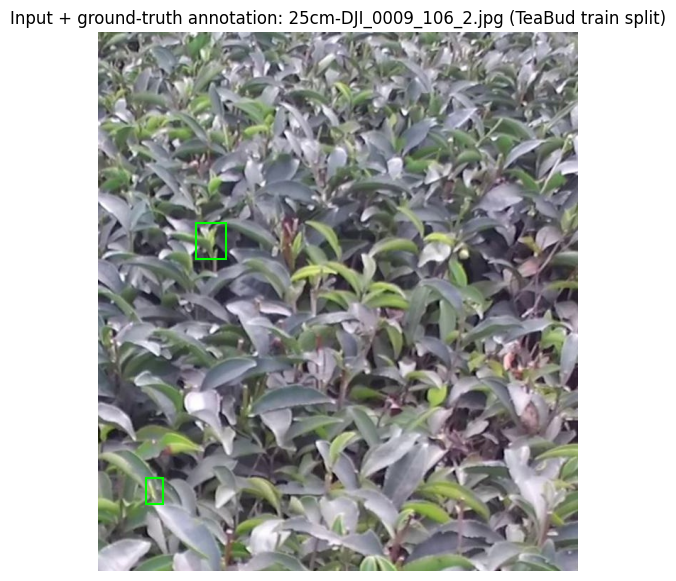

provenance: kagglehub meiling12/tea-budsyolo v1, official train split, author label file


In [ ]:
# Preview one training image with its ground-truth tea_bud annotations
# (green boxes drawn from the author dataset's YOLO label file).
# 学習画像1枚と正解アノテーション（緑枠）を表示します。
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def draw_yolo_labels(ax, img_path, label_path, color="lime", label="GT tea_bud"):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    ax.imshow(im)
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            c, xc, yc, w, h = line.split()[:5]
            xc, yc, w, h = float(xc) * W, float(yc) * H, float(w) * W, float(h) * H
            ax.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h,
                                           fill=False, edgecolor=color, linewidth=1.5,
                                           label=label))
    ax.set_axis_off()

first_img = sorted((DEMO / "images" / "train").glob("*.jpg"))[0]
fig, ax = plt.subplots(figsize=(7, 7))
draw_yolo_labels(ax, first_img, DEMO / "labels" / "train" / (first_img.stem + ".txt"))
ax.set_title(f"Input + ground-truth annotation: {first_img.name} (TeaBud train split)")
plt.show()
print("provenance: kagglehub meiling12/tea-budsyolo v1, official train split, author label file")


## 13. Training-pipeline demonstration (3 epochs / 64 images)
Run the author's training configuration on the demo subset with the MPDIoU loss active. **This validates the pipeline; it does not reproduce the paper's 300-epoch results.** 著者の学習設定でデモサブセットを3エポック学習し、パイプライン動作を確認します（論文結果の再現ではありません）。

In [ ]:
# Belt-and-braces: keep W&B disabled right before training as well.
import os
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_DISABLED"] = "true"
from ultralytics import settings as _usettings
_usettings.update(wandb=False)

# Demonstrate the author's training pipeline with the MPDIoU loss on the demo
# subset, keeping the author's optimizer settings (SGD, lr0=0.01, momentum
# 0.937, wd=5e-4, seed=0, deterministic) but only 3 epochs / 64 images.
# これは学習パイプラインの動作確認であり、論文の300エポック結果とは比較できません。
from ultralytics import YOLO
demo_model = YOLO(PREPARED_YAML)
demo_model.train(
    data=SUBSET_YAML,
    epochs=3, imgsz=640, batch=8,
    optimizer="SGD", lr0=0.01, momentum=0.937, weight_decay=0.0005,
    seed=0, deterministic=True, device=0, amp=True, workers=2,
    plots=False, cache=False,
)
BEST_PT = str(demo_model.trainer.best)
print("best checkpoint:", BEST_PT)


WARNING ⚠️ no model scale passed. Assuming scale='n'.


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.3.9 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)


engine/trainer: task=detect, mode=train, model=/content/clbd-yolo-prepared.yaml, data=/content/tea_demo/tea_demo.yaml, epochs=3, time=None, patience=100, batch=8, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=2, project=None, name=train, exist_ok=False, pretrained=True, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=False, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, show_boxes=True, line_width=None, format=torchscript, keras=False, opt

  0%|          | 0.00/755k [00:00<?, ?B/s]

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  6.31it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  6.17it/s]

                   all         16         31          0          0          0          0


Speed: 0.2ms preprocess, 5.5ms inference, 0.0ms loss, 1.7ms postprocess per image


best checkpoint: runs/detect/train/weights/best.pt


## 14. Quick validation on the demo subset
Metrics from the 3-epoch demo run next to the paper's cited values — labelled explicitly so nobody mistakes the demo numbers for the paper's results. デモ実行の検証結果と、参考として引用した論文値を並べて表示します（比較可能なものではありません）。

In [ ]:
# Quick validation on the 16-image demo val subset. These numbers are from a
# 3-epoch/64-image run and are NOT comparable to the paper's 300-epoch
# results on the 625-image test set (P 74.31 / R 77.07 / mAP50 85.67 /
# mAP50-95 62.69, abstract).
# 3エポック/64枚のデモ結果であり、論文の数値とは比較できません。
import pandas as pd
from ultralytics import YOLO
best = YOLO(BEST_PT)
r = best.val(data=SUBSET_YAML, imgsz=640, device=0, verbose=False)
demo_metrics = pd.DataFrame(
    {"demo subset (3 epochs, 16 val images)": [
        float(r.box.mp), float(r.box.mr), float(r.box.map50), float(r.box.map)]},
    index=["Precision", "Recall", "mAP50", "mAP50-95"],
)
paper_metrics = pd.DataFrame(
    {"paper (300 epochs, 625-image test, cited not reproduced)": [0.7431, 0.7707, 0.8567, 0.6269]},
    index=["Precision", "Recall", "mAP50", "mAP50-95"],
)
display(pd.concat([demo_metrics, paper_metrics], axis=1))
demo_metrics.to_csv("/content/clbd_demo_metrics.csv")
print("saved /content/clbd_demo_metrics.csv")


Ultralytics 8.3.9 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)


clbd-YOLO-prepared summary: 442 layers, 1,424,335 parameters, 0 gradients, 5.7 GFLOPs


val: Scanning /content/tea_demo/labels/val.cache... 16 images, 0 backgrounds, 0 corrupt: 100%|██████████| 16/16 [00:00<?, ?it/s]

val: Scanning /content/tea_demo/labels/val.cache... 16 images, 0 backgrounds, 0 corrupt: 100%|██████████| 16/16 [00:00<?, ?it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   0%|          | 0/1 [00:00<?, ?it/s]

...

                   all         16         31          0          0          0          0


Speed: 0.3ms preprocess, 13.6ms inference, 0.0ms loss, 3.8ms postprocess per image


Results saved to runs/detect/val


,"demo subset (3 epochs, 16 val images)","paper (300 epochs, 625-image test, cited not reproduced)"
Precision,0.0,0.7431
Recall,0.0,0.7707
mAP50,0.0,0.8567
mAP50-95,0.0,0.6269


saved /content/clbd_demo_metrics.csv


## 15. Test image: ground truth vs demo prediction
Run inference on one official test-split image; ground truth is green, demo-model predictions red with confidence. After only 3 epochs the predictions are weak — that is expected and honest. テスト画像で推論し、正解（緑）とデモ予測（赤）を比較します。3エポックのため予測は弱いのが正当な結果です。

test image: 25cm-DJI_0009_107_1.jpg | predictions: 0 | source: kagglehub meiling12/tea-budsyolo v1 test split


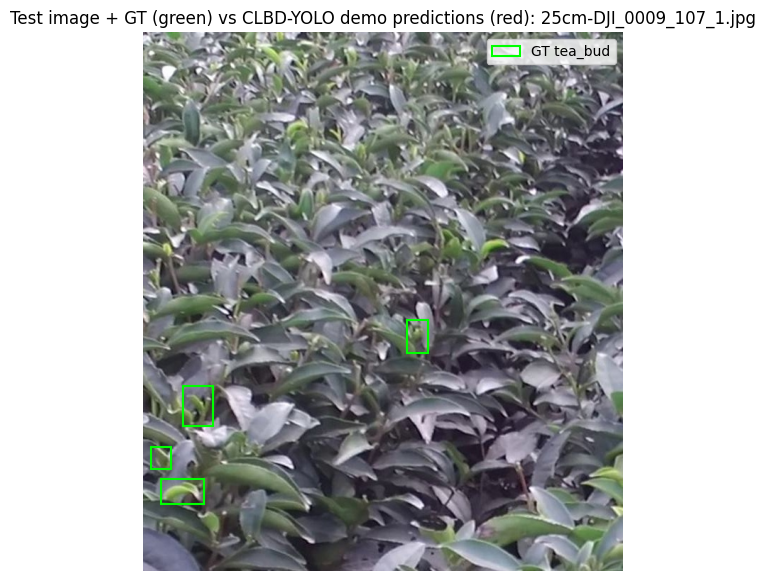

In [ ]:
# Run inference on one official test-split image and compare the model
# prediction (red) with the ground-truth annotation (green).
# テスト画像1枚で推論し、正解（緑）と予測（赤）を重ねて表示します。
import matplotlib.pyplot as plt
from ultralytics import YOLO
test_img = sorted((DATASET_ROOT / "images" / "test").glob("*.jpg"))[0]
res = best.predict(test_img, imgsz=640, conf=0.25, device=0, verbose=False)[0]
print(f"test image: {test_img.name} | predictions: {len(res.boxes)} "
      f"| source: kagglehub meiling12/tea-budsyolo v1 test split")
fig, ax = plt.subplots(figsize=(7, 7))
draw_yolo_labels(ax, test_img, DATASET_ROOT / "labels" / "test" / (test_img.stem + ".txt"),
                 color="lime", label="GT tea_bud")
names = res.names
for b in res.boxes:
    x1, y1, x2, y2 = b.xyxy[0].tolist()
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                               edgecolor="red", linewidth=1.5, label="prediction"))
    ax.text(x1, max(y1 - 4, 4), f"{names[int(b.cls)]} {float(b.conf):.2f}",
            color="white", fontsize=8,
            bbox=dict(facecolor="red", alpha=0.7, pad=1))
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="upper right")
ax.set_title(f"Test image + GT (green) vs CLBD-YOLO demo predictions (red): {test_img.name}")
plt.show()


## 16. Run summary and CSV export
Small exportable table of this run's observed values. 本実行の観測値をCSVに書き出します。

In [ ]:
# Export a small summary of this run (observed values only; no fabricated
# numbers). この実行の観測結果をCSVに書き出します。
import pandas as pd
summary = {
    "item": ["params (observed)", "paper params (cited)",
             "demo train images", "demo val images", "demo epochs",
             "demo mAP50", "demo mAP50-95", "test image predictions"],
    "value": [params, PAPER_PARAMS, N_TRAIN, N_VAL, 3,
              float(r.box.map50), float(r.box.map), len(res.boxes)],
}
df = pd.DataFrame(summary)
display(df)
df.to_csv("/content/clbd_run_summary.csv", index=False)
print("saved /content/clbd_run_summary.csv")


,item,value
0,params (observed),1431439.0
1,paper params (cited),1426000.0
2,demo train images,64.0
3,demo val images,16.0
4,demo epochs,3.0
5,demo mAP50,0.0
6,demo mAP50-95,0.0
7,test image predictions,0.0


saved /content/clbd_run_summary.csv


## 17. Interpretation, differences and references

**What was verified here / 本ノートブックで検証できたこと**
- The author architecture builds from the pinned commit and its complexity matches the paper-reported 1.426 M params / 5.6 GFLOPs (see §8 output).
- The TeaBud Kaggle dataset matches the README (6,242 images, 5055/562/625, single class).
- The author's training pipeline, including the MPDIoU loss integration, runs on a T4 GPU.

**Differences from the paper / 論文との違い**
- No released weights: the demo trains from scratch for 3 epochs on 64 images; all paper metrics are cited, not reproduced.
- `patches/tasks_integration.txt` could not be downloaded by the trusted code-only helper (`.txt` rejected), so the parser integration was re-implemented from module signatures + stock 8.3.9 source; the §8 parameter check is the evidence of fidelity.
- The external 591-image Xinyang Maojian validation subset has no identified public source and is out of scope.

**References / 参考文献**
- Paper: Technologies 14(9):576 (2026), DOI 10.3390/technologies14090576 (abstract-level numbers cited above).
- Code: rnglean/CLBD-YOLO @ 073afc3360bc08b4a9f2c08737eacd59eaa12c4f (README training settings).
- Ultralytics YOLO 8.3.9 (AGPL-3.0) — the runtime patch embeds a modified copy of its `parse_model`/loss body.
- Dataset: Kaggle meiling12/tea-budsyolo v1, CC BY-NC-SA 4.0.
- PhenoPaper investigation p-82224ac1edae6361f8babd4008c53d18-20261022T191823Z-2809234 was used as prior research guidance only; all scientific facts above were re-verified from primary sources.